# Redes Neurais Artificiais 2026.2

- **Disciplina**: Redes Neurais Artificiais 2026.2
- **Professora**: Elloá B. Guedes (ebgcosta@uea.edu.br)  
- **Github**: http://github.com/elloa
- **Alunos**: Bernardo Gontijo (bgfe.eng24@uea.edu.br), Mateus Cabral (mcpi.eng24@uea.edu.br) e Matheus Amazonas (meac.eng24@uea.edu.br) 
        

Levando em conta a base de dados _Dry Bean Dataset_, esta parte do Projeto Prático diz respeito à proposição e avaliação de múltiplas redes neurais artificiais do tipo feedforward multilayer perceptron para o problema da classificação multiclasse de variedades de feijão seco a partir de características geométricas extraídas de imagens dos grãos.

## Busca em Grade

Uma maneira padrão de escolher os parâmetros de um modelo de Machine Learning é por meio de uma busca em grade via força bruta. O algoritmo da busca em grade é dado como segue:

1. Escolha a métrica de desempenho que você deseja maximizar (por exemplo, o F-Score com média macro, adequado a um problema multiclasse com classes desbalanceadas)  
2. Escolha o algoritmo de Machine Learning (exemplo: redes neurais artificiais). Em seguida, defina os parâmetros ou hiperparâmetros deste tipo de modelo sobre os quais você deseja otimizar (número de épocas, taxa de aprendizado, etc.) e construa um array de valores a serem testados para cada parâmetro ou hiperparâmetro.  
3. Defina a grade de busca, a qual é dada como o produto cartesiano dos valores de cada parâmetro a ser testado. Por exemplo, para os arrays [50, 100, 1000] e [10, 15], tem-se que a grade é [(50,10), (50,15), (100,10), (100,15), (1000,10), (1000,15)].
4. Para cada combinação de parâmetros a serem otimizados, utilize _apenas o conjunto de treinamento_ para realizar uma validação cruzada (holdout ou k-fold) e calcule a métrica de avaliação nos conjuntos de validação gerados por ela. O conjunto de teste não participa da busca. Vamos efetuar validação cruzada holdout 70/30 estratificada.
5. Escolha a combinação de parâmetros que maximiza a métrica de avaliação na validação. Este é o modelo otimizado, que deve então ser reavaliado uma única vez no conjunto de teste.

Por que esta abordagem funciona? Porque a busca em grade efetua uma pesquisa extensiva sobre as possíveis combinações de valores para cada um dos parâmetros a serem ajustados. Para cada combinação, ela estima a performance do modelo em dados não utilizados no seu treinamento (os conjuntos de validação). Por fim, o modelo com melhor métrica de desempenho é escolhido. Tem-se então que este modelo é o que tem maior chance de generalizar bem mediante dados nunca antes vistos, e o conjunto de teste, que não foi utilizado na busca, fornece a estimativa final e não enviesada desse desempenho.

## Efetuando a Busca em Grade sobre Hiperparâmetros das Top-6 RNAs

Considerando a etapa anterior do projeto prático, foram identificadas pelo menos 6 melhores Redes Neurais para o problema da classificação multiclasse das variedades de feijão no conjunto de dados selecionado. Estas redes podem ter sido obtidas pela estratégia própria ou pela regra da Pirâmide Geométrica, e todas utilizam os 16 atributos numéricos como preditores.

A primeira etapa desta segunda parte do projeto consiste em trazer para este notebook estas seis arquiteturas, ressaltando:

1. Número de neurônios ocultos por camada  
2. Função de Ativação  
3. Estratégia de origem da arquitetura (Própria ou Pirâmide Geométrica)  
4. Desempenho médio ± desvio padrão nos testes anteriores  
5. Número de repetições que a equipe conseguiu realizar para verificar os resultados  

Elabore uma busca em grade sobre estas arquiteturas que contemple variações nos hiperparâmetros a seguir, conforme documentação de [MLPClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html)

A. Solver (não usar o LBFGS, pois é mais adequado para datasets pequenos)  
B. Batch Size  
C. Learning Rate Init  
D. Paciência 
E. Épocas  

Nesta busca em grade, contemple a utilização do objeto [GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html), com a métrica escolhida no parâmetro `scoring` (por exemplo, `'f1_macro'`) e a validação cruzada realizada apenas com o conjunto de treinamento (já escalonado conforme a estratégia da etapa anterior).

## Validação Cruzada k-fold

Na elaboração da busca em grade, vamos avaliar os modelos propostos segundo uma estratégia de validação cruzada ainda não explorada até o momento: a validação cruzada *k-fold*. Segundo a mesma, o conjunto de dados é particionado em *k* partes (*folds*): a cada iteração, separa-se uma das partes para validação e o modelo é treinado com as *k-1* partes remanescentes. Valores sugestivos de *k* na literatura são *k* = 3, 5 ou 10, pois o custo computacional desta validação dos modelos é alto. A métrica de desempenho é resultante da média dos desempenhos nas *k* iterações. A figura a seguir ilustra a ideia desta avaliação:

<img src="https://ethen8181.github.io/machine-learning/model_selection/img/kfolds.png" width="600">

Considerando a métrica de desempenho F1-Score (com média macro, dado que o problema possui 7 classes), considere a validação cruzada 5-fold estratificada para aferir os resultados da busca em grade anterior, realizada *apenas com o conjunto de treinamento*. O conjunto de teste deve ser utilizado uma única vez, para avaliar a melhor configuração encontrada.

A busca usa o conjunto de desenvolvimento reservado na etapa 2. A padronização faz parte do Pipeline, então o escalonador é ajustado no treino de cada fold. A paciência controla quantas épocas de treino sem melhora suficiente na perda são toleradas.

In [1]:
from ast import literal_eval
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import sklearn
import pandas as pd
from joblib import cpu_count, parallel_config
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, ParameterGrid
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay, accuracy_score, f1_score
)
from threadpoolctl import threadpool_limits
from sklearn.base import clone


In [2]:
raiz = Path.cwd()
if raiz.name == "Notebooks":
    raiz = raiz.parent

df = pd.read_excel(raiz / "DryBeanDataset" / "Dry_Bean_Dataset.xlsx")
y = df["Class"]
X = df.drop("Class", axis=1)

# Reproduzimos a separação externa feita no notebook da etapa 2.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=64
)

top_6 = pd.read_csv(raiz / "Notebooks" / "top_6_rnas.csv", converters={"camadas": literal_eval})
display(top_6.drop(columns="limites_atingidos").round(4))

,arquitetura,camadas,ativação,estratégia,solver,épocas,repetições,acc_média,acc_std,f1_média,f1_std
0,"N7: (32,16) relu","(32, 16)",relu,Própria,adam,200,10,0.9261,0.0043,0.9382,0.0040
1,"α=3 Nh=32 2c 75/25 (24, 8) relu","(24, 8)",relu,Pirâmide Geométrica,adam,200,10,0.9259,0.0039,0.9378,0.0037
2,N2: (32) relu,"(32,)",relu,Própria,adam,150,10,0.9257,0.0035,0.9375,0.0036
3,"α=2 Nh=21 1c (21,) relu","(21,)",relu,Pirâmide Geométrica,adam,200,10,0.9256,0.0041,0.9374,0.0037
4,"α=3 Nh=32 2c 50/50 (16, 16) relu","(16, 16)",relu,Pirâmide Geométrica,adam,200,10,0.9257,0.0045,0.9372,0.0039
5,"N6: (16,8) relu","(16, 8)",relu,Própria,adam,200,10,0.9253,0.0041,0.9371,0.0039


A tabela reúne as seis melhores arquiteturas da etapa 2: três da estratégia própria (N7, N2 e N6) e três da regra da Pirâmide Geométrica. Todas usam ativação ReLU e foram avaliadas com 10 repetições, cada uma com uma partição holdout 70/30 estratificada diferente. Os desempenhos médios ficaram muito próximos, com F1 macro entre 0.9371 e 0.9382 e desvios padrão em torno de 0.004. Ou seja, as diferenças entre elas são menores que a variação entre as repetições, e isso justifica levar as seis para a busca em grade em vez de escolher uma só.

In [3]:
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("mlp", MLPClassifier(random_state=64))
])

# Cada arquitetura conserva a função de ativação escolhida na etapa 2.
grade = []
for _, r in top_6.iterrows():
    grade.append({
        "mlp__hidden_layer_sizes": [r["camadas"]],
        "mlp__activation": [r["ativação"]],
        "mlp__solver": ["adam", "sgd"],
        "mlp__batch_size": [128, 256],
        "mlp__learning_rate_init": [0.001, 0.01],
        "mlp__n_iter_no_change": [10, 20],
        "mlp__max_iter": [100, 200],
    })

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=64)
n_jobs = min(8, cpu_count())
busca = GridSearchCV(
    pipeline, grade, scoring="f1_macro", cv=cv, refit=True,
    n_jobs=n_jobs, pre_dispatch=n_jobs, verbose=1, error_score="raise"
)

n_config = len(ParameterGrid(grade))
print(f"{n_config} configurações e {n_config * cv.get_n_splits()} ajustes nos folds.")

192 configurações e 960 ajustes nos folds.


In [4]:
with parallel_config(backend="loky", inner_max_num_threads=1):
    with threadpool_limits(limits=1, user_api="blas"):
        busca.fit(X_train, y_train)

Fitting 5 folds for each of 192 candidates, totalling 960 fits


## Identificando a mellhor solução

Como resultado da busca em grade com validação cruzada 5-fold, identifique o modelo otimizado com melhor desempenho para o problema. Apresente claramente este modelo, sua arquitetura (número de camadas ocultas, neurônios por camada e função de ativação), os hiperparâmetros otimizados (solver, batch size, taxa de aprendizado inicial, paciência e épocas) e os resultados (F1-Score macro) para cada um dos folds avaliados, junto com a média ± desvio padrão entre os folds. Em seguida, reavalie este modelo uma única vez no conjunto de teste, apresentando a matriz de confusão, a acurácia e o F1-Score macro. Esta é a melhor solução identificada em decorrência deste projeto.

In [5]:
modelo = busca.best_estimator_
mlp = modelo.named_steps["mlp"]
melhor = busca.best_index_
resultados = busca.cv_results_

print(f"Camadas ocultas: {len(mlp.hidden_layer_sizes)}")
print(f"Neurônios por camada: {mlp.hidden_layer_sizes}")
print(f"Ativação: {mlp.activation}")
print(f"Solver: {mlp.solver}")
print(f"Batch size: {mlp.batch_size}")
print(f"Taxa de aprendizado inicial: {mlp.learning_rate_init}")
print(f"Paciência: {mlp.n_iter_no_change}")
print(f"Máximo de épocas: {mlp.max_iter}")

f1s = [resultados[f"split{i}_test_score"][melhor] for i in range(cv.get_n_splits())]
display(pd.DataFrame({"Fold": range(1, len(f1s) + 1), "F1 macro": f1s}).round(4))
print(f"F1 macro na validação: {busca.best_score_:.4f} ± {resultados['std_test_score'][melhor]:.4f}")

Camadas ocultas: 1
Neurônios por camada: (21,)
Ativação: relu
Solver: adam
Batch size: 128
Taxa de aprendizado inicial: 0.01
Paciência: 10
Máximo de épocas: 200


,Fold,F1 macro
0,1,0.9413
1,2,0.9446
2,3,0.9405
3,4,0.9379
4,5,0.9441


F1 macro na validação: 0.9417 ± 0.0025


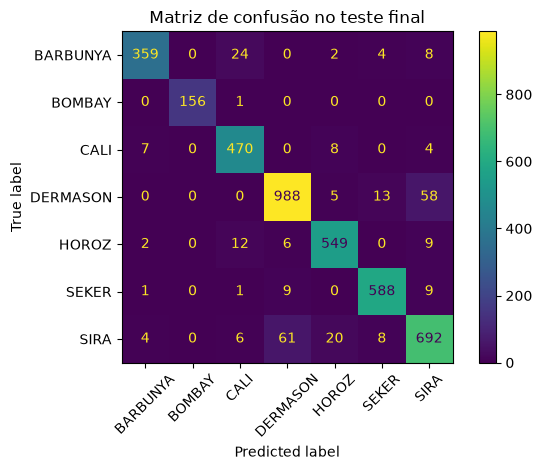

Acurácia no teste: 0.9310
F1 macro no teste: 0.9406


In [6]:
y_pred = modelo.predict(X_test)
classes = modelo.classes_
cm = confusion_matrix(y_test, y_pred, labels=classes)
ConfusionMatrixDisplay(cm, display_labels=classes).plot(xticks_rotation=45)
plt.title("Matriz de confusão no teste final")
plt.tight_layout()
plt.show()

acc = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred, average="macro")
print(f"Acurácia no teste: {acc:.4f}")
print(f"F1 macro no teste: {f1:.4f}")

## Empacotando a solução

Suponha que você deve entregar este classificador a uma cooperativa ou órgão responsável pelo controle de qualidade e classificação de grãos de feijão seco. Para tanto, você deve fazer uma preparação do mesmo para utilização neste cenário. Uma vez que já identificou os melhores hiperparâmetros, o passo remanescente consiste em treinar o modelo com estes valores e todos os dados disponíveis, salvando o modelo treinado (pesos da rede e o escalonador dos atributos) ao final para entrega ao cliente. Assim, finalize o projeto prático realizando tais passos.

1. Consulte a documentação a seguir:
https://scikit-learn.org/stable/modules/model_persistence.html  
2. Treine o modelo com todos os dados, utilizando a arquitetura e os hiperparâmetros otimizados. O escalonador (`StandardScaler`) deve ser ajustado com todos os dados e salvo junto com a rede, preferencialmente em um único `Pipeline`  
3. Salve o modelo em disco  
4. Construa uma rotina que recupere o modelo em disco  
5. Mostre que a rotina é funcional, fazendo previsões com todos os elementos do dataset e exibindo uma matriz de confusão das mesmas. Como o modelo foi treinado com todos os dados, esta matriz serve apenas para verificar o funcionamento da rotina e não como estimativa de desempenho, que é dada pelos resultados da validação cruzada e do conjunto de teste

Modelo salvo em classificador_feijao.joblib (scikit-learn 1.9.1).
Previsões conferidas após recarregar: 13611.


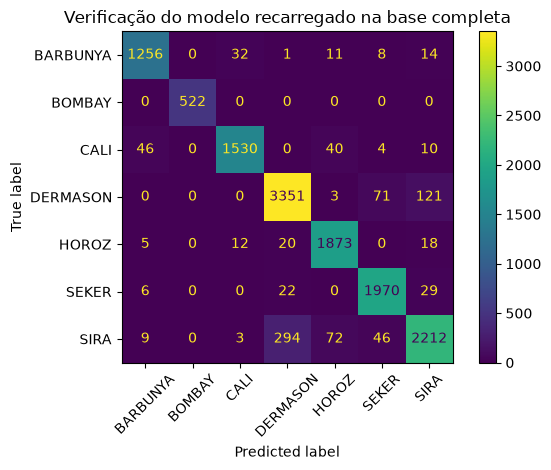

In [7]:
modelo_final = clone(modelo)
with threadpool_limits(limits=1, user_api="blas"):
    modelo_final.fit(X, y)

caminho_modelo = raiz / "Notebooks" / "classificador_feijao.joblib"
joblib.dump(modelo_final, caminho_modelo)
print(f"Modelo salvo em {caminho_modelo.name} (scikit-learn {sklearn.__version__}).")

def carrega_modelo(caminho):
    return joblib.load(caminho)

modelo_carregado = carrega_modelo(caminho_modelo)
y_pred = modelo_carregado.predict(X)
np.testing.assert_array_equal(y_pred, modelo_final.predict(X))
print(f"Previsões conferidas após recarregar: {len(y_pred)}.")

classes = modelo_carregado.classes_
cm = confusion_matrix(y, y_pred, labels=classes)
ConfusionMatrixDisplay(cm, display_labels=classes).plot(xticks_rotation=45)
plt.title("Verificação do modelo recarregado na base completa")
plt.tight_layout()
plt.show()

## Conclusão

A melhor solução encontrada foi a rede de uma camada oculta com 21 neurônios e ativação ReLU, obtida pela regra da Pirâmide Geométrica e treinada com adam, batch size 128, taxa de aprendizado inicial 0.01, paciência 10 e até 200 épocas. Na validação cruzada 5-fold, ela obteve F1 macro de 0.9417 ± 0.0025, e no conjunto de teste alcançou acurácia de 0.9310 e F1 macro de 0.9406. A proximidade entre os resultados de validação e teste indica que a busca em grade não deu overfitting nos hiperparâmetros. Como as seis arquiteturas da etapa 2 tinham desempenhos muito próximos, o ajuste dos hiperparâmetros de treino foi o que definiu a melhor rede. A configuração vencedora ficou no limite da grade em alguns hiperparâmetros, então ampliar os valores testados pode trazer ganhos. Os erros restantes se concentram em variedades de formato parecido, principalmente SIRA e DERMASON e, em menor grau, BARBUNYA e CALI, o que mostra uma limitação dos atributos geométricos para separá-las. O modelo final foi treinado com todos os dados e salvo em um único Pipeline, junto com o escalonador, para ser entregue ao cliente.